# 3.2A — Profils de trajets à vélo

**Objectif :** découvrir et interpréter des groupes de trajets à partir de leurs propriétés et de leurs usages, conformément à l'énoncé, pages 2–3.

Une ligne représente un trajet. Deux lectures complémentaires sont retenues : **durée–déplacement** et **contexte d'échange entre les stations**. Elles sont ensuite croisées sur les mêmes observations. Les autres pistes sont résumées à la fin.

Notebook autonome : il lit les CSV du dossier `data`. Les décisions chronologiques restent dans [choix.md](choix.md). Les annotations sont un support de travail à comprendre et à réécrire personnellement pour la remise, conformément à l'énoncé.

## 1. Préparation commune

Jointures gauches vérifiées : `trips → cities`, `trips → bikes → bike_types`, puis `stations` pour chaque extrémité. Les identifiants restent des clés de jointure, jamais des grandeurs numériques de clustering. `stations_status` n'est pas nécessaire aux deux représentations retenues.

Le déplacement fourni est la distance à vol d'oiseau entre les extrémités. Le taux déplacement/durée est descriptif ; l'ajouter aux deux autres mesures serait redondant. Les horaires sont convertis dans le fuseau local de chaque système, avec prise en compte des changements d'heure.

In [1]:
from pathlib import Path
import os
os.environ.setdefault('LOKY_MAX_CPU_COUNT','2')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.model_selection import GroupShuffleSplit
from threadpoolctl import threadpool_limits

ROOT = Path.cwd()
if not (ROOT / 'data/trips_small.csv').exists():
    ROOT = ROOT.parent
DATA = ROOT / 'data'
assert (DATA / 'trips_small.csv').exists(), 'Lancer depuis le projet ou zaka.'

pd.set_option('display.max_columns', 10)
pd.set_option('display.max_rows', 12)
plt.rcParams.update({'font.size': 10, 'figure.dpi': 110,
                     'axes.spines.top': False, 'axes.spines.right': False})

import platform
import sklearn
print(f'Python {platform.python_version()} ; pandas {pd.__version__} ; '
      f'NumPy {np.__version__} ; scikit-learn {sklearn.__version__}')


Python 3.12.0 ; pandas 2.2.3 ; NumPy 2.3.5 ; scikit-learn 1.9.0


In [2]:
trips = pd.read_csv(DATA / 'trips_small.csv', usecols=[
    'bike_id', 'city_id', 'time_start', 'duration', 'distance',
    'lon_start', 'lat_start', 'lon_end', 'lat_end',
    'station_id_start', 'station_id_end'])
cities = pd.read_csv(DATA / 'cities.csv', usecols=[
    'id', 'name', 'lat', 'lon', 'timezone', 'return_to_official_only'])
bikes = pd.read_csv(DATA / 'bikes.csv', usecols=['id', 'bike_type_id'])
types = pd.read_csv(DATA / 'bike_types.csv', usecols=[
    'id', 'propulsion_type', 'form_factor', 'rider_capacity'])
stations = pd.read_csv(DATA / 'stations.csv', usecols=['id', 'lon', 'lat'])

assert not trips.duplicated(['bike_id', 'time_start']).any()
for ref in [cities, bikes, types, stations]:
    assert ref['id'].notna().all() and ref['id'].is_unique

# Réunir les informations : une ligne reste un trajet.

n_trips = len(trips)
table = trips.copy()
table['trip_row'] = np.arange(n_trips)

city_info = cities.rename(columns={
    'id': 'city_id', 'name': 'city_name', 'lat': 'city_lat', 'lon': 'city_lon'})
bike_info = bikes.rename(columns={'id': 'bike_id'})
type_info = types.rename(columns={'id': 'bike_type_id'})
start_info = stations.rename(columns={
    'id': 'station_id_start', 'lon': 'station_start_lon', 'lat': 'station_start_lat'})
end_info = stations.rename(columns={
    'id': 'station_id_end', 'lon': 'station_end_lon', 'lat': 'station_end_lat'})

table = table.merge(city_info, on='city_id', how='left', validate='many_to_one')
table = table.merge(bike_info, on='bike_id', how='left', validate='many_to_one')
table = table.merge(type_info, on='bike_type_id', how='left', validate='many_to_one')
table = table.merge(start_info, on='station_id_start', how='left', validate='many_to_one')
table = table.merge(end_info, on='station_id_end', how='left', validate='many_to_one')
assert len(table) == n_trips and table.trip_row.is_unique

# Conserver aussi le bilan détaillé de chaque jointure.
join_log = []
references = [
    ('city_id', cities, 'cities'),
    ('bike_id', bikes, 'bikes'),
    ('bike_type_id', types, 'bike_types'),
    ('station_id_start', stations, 'stations — start'),
    ('station_id_end', stations, 'stations — end'),
]
for key, reference, label in references:
    missing_key = table[key].isna()
    matched = table[key].isin(reference['id'])
    unmatched = ~matched & ~missing_key
    join_log.append({
        'jointure': label,
        'trajets': len(table),
        'clé absente': int(missing_key.sum()),
        'clé renseignée sans correspondance': int(unmatched.sum()),
        '% correspondance': round(100 * matched.mean(), 2),
    })


In [3]:
table['duration_min'] = table['duration'] / 60
# La distance fournie est un déplacement entre les extrémités.
table['displacement_km'] = table['distance'] / 1000
valid_motion = table['duration_min'].gt(0) & table['displacement_km'].ge(0)
table['displacement_rate_kmh'] = (
    table['displacement_km'] / (table['duration_min'] / 60)
).where(valid_motion)

utc_start = pd.to_datetime(table['time_start'], unit='s', utc=True, errors='coerce')
table['local_start_hour'] = np.nan
table['local_weekday'] = pd.Series(pd.NA, index=table.index, dtype='Int64')
# Conversion séparée par fuseau : pas de fuseau commun imposé aux horaires locaux.
for timezone, indices in table.groupby('timezone', dropna=True).groups.items():
    local = utc_start.loc[indices].dt.tz_convert(timezone)
    table.loc[indices, 'local_start_hour'] = (
        local.dt.hour + local.dt.minute/60 + local.dt.second/3600)
    table.loc[indices, 'local_weekday'] = local.dt.dayofweek.astype('Int64')
table['weekend'] = table['local_weekday'].ge(5).astype('Int64')

# Deux composantes d'une même heure ; l'heure brute reste disponible pour la lecture.
hour_angle = 2 * np.pi * table['local_start_hour'] / 24
table['start_hour_sin'] = np.sin(hour_angle)
table['start_hour_cos'] = np.cos(hour_angle)
# Conserver la géométrie circulaire : même facteur de pondération pour les deux axes.
assert np.allclose((table['start_hour_sin']**2 + table['start_hour_cos']**2).dropna(), 1)

# Vérifications : les coordonnées hors limites ne sont pas utilisées comme positions valides.
coordinate_audit = []
position_columns = ['lon_start', 'lat_start', 'lon_end', 'lat_end',
                    'station_start_lon', 'station_start_lat', 'station_end_lon', 'station_end_lat']
for col in position_columns:
    limit = 90 if 'lat' in col else 180
    invalid = table[col].notna() & (~np.isfinite(table[col]) | table[col].abs().gt(limit))
    coordinate_audit.append({'variable':col, 'hors limites':int(invalid.sum())})
    table.loc[invalid, col] = np.nan


# Hypothèse conservée uniquement en description ; valeur originale non modifiée.
table['rider_capacity_filled']=table.rider_capacity.fillna(1)
table['multiple_seats']=table.rider_capacity_filled.gt(1).astype('Int64')
trips=table.reset_index(drop=True)
del table
assert trips.trip_row.is_unique
assert trips[['duration_min','displacement_km']].gt(0).all().all()
assert np.isfinite(trips[['duration_min','displacement_km']]).all().all()

cutoffs=trips.groupby('city_id').time_start.quantile([.6,.8]).unstack()
trips['period']=np.select([trips.time_start.le(trips.city_id.map(cutoffs[.6])),
    trips.time_start.le(trips.city_id.map(cutoffs[.8]))],['train','validation'],default='test')
trips['propulsion_context']=trips.propulsion_type.fillna('inconnu')
audit_groups={
    'Durée / déplacement':(['duration_min','displacement_km'],'Requis pour le modèle physique'),
    'Heure locale / weekend':(['local_start_hour','weekend'],'Requis pour les signatures et la description'),
    'Propulsion / forme':(['propulsion_type','form_factor'],'Descripteurs : absence conservée'),
    'Nombre de places':(['rider_capacity'],'Une place par défaut, descripteur seulement'),
    'Coordonnées de départ station':(['station_start_lat','station_start_lon'],'Pas d’imputation ; contrôle géographique'),
    'Coordonnées d’arrivée station':(['station_end_lat','station_end_lon'],'Pas d’imputation ; contrôle géographique')}
missing_audit=pd.DataFrame([{'Information':name,'Absence (%)':100*trips[cols].isna().any(axis=1).mean(),
    'Décision':decision}for name,(cols,decision)in audit_groups.items()]).set_index('Information')
display(missing_audit.round(2))
print(f'{len(trips):,} trajets ; {trips.city_id.nunique()} systèmes ; '
      f'{100*trips.duration.mod(60).eq(0).mean():.1f} % de durées multiples de 60 secondes.')

,Absence (%),Décision
Information,,
Durée / déplacement,0.00,Requis pour le modèle physique
Heure locale / weekend,0.00,Requis pour les signatures et la description
Propulsion / forme,0.20,Descripteurs : absence conservée
Nombre de places,0.20,"Une place par défaut, descripteur seulement"
Coordonnées de départ station,9.12,Pas d’imputation ; contrôle géographique
Coordonnées d’arrivée station,17.04,Pas d’imputation ; contrôle géographique


1,161,376 trajets ; 185 systèmes ; 96.9 % de durées multiples de 60 secondes.


**Périmètres :** les deux modèles n'utilisent ni propulsion ni forme comme variables actives ; les 2 346 trajets sans ces informations sont donc conservés, contrairement à certains essais initiaux. Aucune valeur de station ni coordonnée n'est inventée. Une signature de station absente entraînera une exclusion limitée à la lecture fonctionnelle.

Les valeurs extrêmes restent dans l'analyse principale. Les bornes observées — environ 2–480 min, 50 m–20 km et 0,25–15 km/h de taux — suggèrent une sélection préalable non documentée. Ni les durées longues ni les faibles taux ne sont assimilés à des erreurs.

**Séparation temporelle par système :** premiers 60 % pour apprendre les références et modèles, 20 % suivants pour comparer, 20 % derniers pour décrire les résultats. Ces périodes ont été consultées pendant l'exploration : il s'agit de contrôles internes, pas d'un test externe resté aveugle.

### Construire le contexte historique des stations

Pour chaque station, on calcule en semaine la part des départs et la part des arrivées dans huit tranches de trois heures, puis leur différence. Les distributions sont normalisées séparément : c'est un **rythme relatif**, pas un bilan absolu de vélos.

Seuls les événements antérieurs à la coupure de 60 % sont utilisés. Une arrivée est datée avec la durée réelle, puis convertie localement. Lissage : trois observations par tranche ; support minimal : 100 départs **et** 100 arrivées. Les deux signatures sont rattachées à chaque trajet : 16 colonnes, sans identité numérique de station.

In [4]:
known_stations = set(stations.id)
event_parts = []
for side,direction in [('start',1),('end',-1)]:
    valid = trips[f'station_id_{side}'].isin(known_stations)
    e = trips.loc[valid,['city_id',f'station_id_{side}','time_start','duration','timezone']].copy()
    e = e.rename(columns={f'station_id_{side}':'station'})
    e['event_time'] = e.time_start + (e.duration if side=='end' else 0)
    utc = pd.to_datetime(e.event_time,unit='s',utc=True)
    e['hour'],e['weekday'] = np.nan,np.nan
    for tz,indices in e.groupby('timezone').groups.items():
        local = utc.loc[indices].dt.tz_convert(tz)
        e.loc[indices,'hour'] = local.dt.hour
        e.loc[indices,'weekday'] = local.dt.dayofweek
    e['direction'] = direction
    e['old'] = e.event_time.le(e.city_id.map(cutoffs[.6]))
    event_parts.append(e[['city_id','station','hour','weekday','direction','old']])
events = pd.concat(event_parts,ignore_index=True)
events = events.loc[events.weekday.lt(5)].copy()
events['bin'] = (events.hour//3).astype(int)
del event_parts

def station_signatures(events_subset, alpha=3, min_events=100):
    keys = ['city_id', 'station', 'bin']
    departures = events_subset.loc[events_subset.direction == 1]
    arrivals = events_subset.loc[events_subset.direction == -1]

    departures = departures.groupby(keys).size().unstack('bin', fill_value=0)
    arrivals = arrivals.groupby(keys).size().unstack('bin', fill_value=0)
    departures = departures.reindex(columns=range(8), fill_value=0)
    arrivals = arrivals.reindex(columns=range(8), fill_value=0)
    n_departures = departures.sum(axis=1)
    n_arrivals = arrivals.sum(axis=1)

    departure_share = (departures + alpha).div(n_departures + 8 * alpha, axis=0)
    arrival_share = (arrivals + alpha).div(n_arrivals + 8 * alpha, axis=0)
    signature = departure_share - arrival_share
    support = pd.concat([n_departures, n_arrivals], axis=1).min(axis=1)
    signature = signature.loc[support >= min_events].dropna()
    assert np.allclose(signature.sum(axis=1), 0)
    return signature, support


def attach_signatures(frame, signature):
    start = signature.add_prefix('start_')
    end = signature.add_prefix('end_')
    columns = list(start.columns) + list(end.columns)
    result = frame.join(start, on=['city_id', 'station_id_start'], validate='many_to_one')
    result = result.join(end, on=['city_id', 'station_id_end'], validate='many_to_one')
    return result.dropna(subset=columns), columns

# Rattacher les deux signatures à chaque trajet : 16 variables.

old_signatures,old_support = station_signatures(events.loc[events.old])
flow_trips,flow_columns = attach_signatures(trips,old_signatures)
flow_trips = flow_trips.reset_index(drop=True)
flow_X = flow_trips[flow_columns].to_numpy()
assert flow_trips.trip_row.is_unique and np.isfinite(flow_X).all()
print(f'{len(flow_trips):,} trajets ({100*len(flow_trips)/len(trips):.1f} % du fichier), '
      f'{flow_trips.city_id.nunique()} systèmes, {len(old_signatures):,} couples système–station documentés.')
print(f'{len(trips)-len(flow_trips):,} trajets hors de cette piste : stations inconnues, absentes ou trop peu observées.')

692,835 trajets (59.7 % du fichier), 111 systèmes, 1,064 couples système–station documentés.
468,541 trajets hors de cette piste : stations inconnues, absentes ou trop peu observées.


## 2. Profils physiques : durée et déplacement

**Hypothèse :** pour un déplacement comparable, des durées différentes peuvent caractériser des formes de voyage distinctes.

Variables : log(durée) et log(déplacement), standardisées sur 80 000 trajets d'apprentissage. Le logarithme atténue l'influence des grandes valeurs sans supprimer de trajets. Le GMM autorise des groupes allongés et des appartenances incertaines.

On compare une à huit composantes. Le critère retenu est le BIC augmenté de deux fois l'entropie des appartenances, approximation de l'ICL : il pénalise les composantes qui se recouvrent. Une meilleure estimation de densité ne signifie pas nécessairement davantage de profils.

In [5]:
# Même ordre des tirages que dans la version précédente.
rng = np.random.default_rng(2026)
period_ids = {}
for period in ['train', 'validation', 'test']:
    period_ids[period] = np.flatnonzero(trips.period == period)
physical_train = rng.choice(period_ids['train'], 80000, replace=False)
physical_valid = rng.choice(period_ids['validation'], 25000, replace=False)
physical_test = rng.choice(period_ids['test'], 30000, replace=False)

log_motion = np.log(trips[['duration_min', 'displacement_km']].to_numpy())
motion_scaler = StandardScaler().fit(log_motion[physical_train])
motion_X = motion_scaler.transform(log_motion)

mixtures = {}
physical_rows = []
with threadpool_limits(limits=2):
    for k in range(1, 9):
        model = GaussianMixture(n_components=k, n_init=4, max_iter=300,
                                reg_covar=1e-4, random_state=42)
        model.fit(motion_X[physical_train])
        assert model.converged_
        probabilities = model.predict_proba(motion_X[physical_train])
        entropy = -(probabilities * np.log(np.maximum(probabilities, 1e-15))).sum()
        validation_probability = model.predict_proba(motion_X[physical_valid]).max(axis=1)
        physical_rows.append({
            'K': k,
            'BIC': model.bic(motion_X[physical_train]),
            'Log-vraisemblance validation': model.score(motion_X[physical_valid]),
            'converged': model.converged_,
            'ICL_approx': model.bic(motion_X[physical_train]) + 2 * entropy,
            'Appartenance ≥ 0,8 (%)': 100 * (validation_probability >= 0.8).mean()})
        mixtures[k] = model

physical_comparison = pd.DataFrame(physical_rows).set_index('K')
physical_k = int(physical_comparison.ICL_approx.idxmin())
motion_model = mixtures[physical_k]
motion_raw = motion_model.predict(motion_X)

# Les numéros sont rangés par taux médian décroissant, après le clustering.
median_rates = trips.groupby(motion_raw).displacement_rate_kmh.median()
order = median_rates.sort_values(ascending=False).index
motion_mapping = dict(zip(order, range(1, physical_k + 1)))
trips['forme_trajet'] = pd.Series(motion_raw).map(motion_mapping).to_numpy()
trips['motion_probability'] = motion_model.predict_proba(motion_X).max(axis=1)

display(physical_comparison.rename(columns={'ICL_approx': 'ICL approximé'}).round(1))
print(f'{physical_k} composantes retenues par le critère ; '
      f'{100 * trips.motion_probability.lt(.8).mean():.1f} % des trajets restent ambigus au seuil 0,8.')

,BIC,Log-vraisemblance validation,converged,ICL approximé,"Appartenance ≥ 0,8 (%)"
K,,,,,
1,422968.9,-2.7,True,422968.9,100.0
2,361046.5,-2.3,True,395812.1,90.1
3,360162.9,-2.3,True,441968.7,52.4
4,359920.7,-2.3,True,462004.3,35.8
5,359453.3,-2.3,True,470161.3,32.1
6,358947.2,-2.3,True,475015.6,32.1
7,356196.3,-2.3,True,485022.1,25.8
8,356192.4,-2.3,True,481809.7,30.0


2 composantes retenues par le critère ; 9.8 % des trajets restent ambigus au seuil 0,8.


,Part_pct,Durée_min,Déplacement_km,Taux_kmh
forme_trajet,,,,
Déplacement en peu de temps,77.64,10.0,1.36,8.38
Durée élevée pour le déplacement,22.36,33.0,1.27,2.69


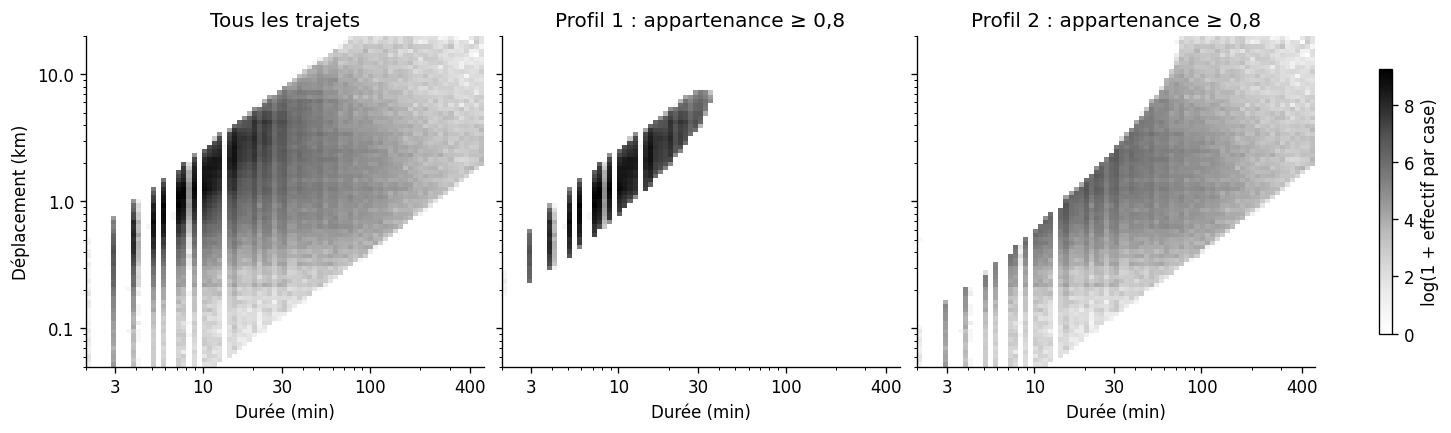

In [6]:
motion_names = {1:'Déplacement en peu de temps',2:'Durée élevée pour le déplacement'}
physical_profiles = trips.groupby('forme_trajet').agg(
    Effectif=('trip_row','size'), Durée_min=('duration_min','median'),
    Déplacement_km=('displacement_km','median'), Taux_kmh=('displacement_rate_kmh','median'),
    Weekend_pct=('weekend',lambda s:100*s.mean()),
    Electrique_pct=('propulsion_type',lambda s:100*s.eq('electric_assist').mean()))
physical_profiles.insert(1,'Part_pct',100*physical_profiles.Effectif/len(trips))
display(physical_profiles[['Part_pct','Durée_min','Déplacement_km','Taux_kmh']].rename(index=motion_names).round(2))

# Même grille et même échelle de comptage : pas de frontières colorées imposées.
edges = [np.linspace(np.log(2),np.log(480),80),np.linspace(np.log(.05),np.log(20),80)]
fig, axes = plt.subplots(1,3,figsize=(12,3.5),sharex=True,sharey=True,layout='constrained')
selections = [np.ones(len(trips),dtype=bool)] + [
    (trips.forme_trajet.eq(k)&trips.motion_probability.ge(.8)).to_numpy() for k in [1,2]]
histograms = [np.histogram2d(log_motion[s,0],log_motion[s,1],bins=edges)[0] for s in selections]
vmax = max(np.log1p(h).max() for h in histograms)
for ax,h,title in zip(axes,histograms,['Tous les trajets','Profil 1 : appartenance ≥ 0,8','Profil 2 : appartenance ≥ 0,8']):
    im=ax.pcolormesh(np.exp(edges[0]),np.exp(edges[1]),np.log1p(h.T),cmap='Greys',vmin=0,vmax=vmax,rasterized=True)
    ax.set(xscale='log',yscale='log',xlabel='Durée (min)',title=title)
for ax in axes:
    ax.set_xticks([3,10,30,100,400])
    ax.set_yticks([.1,1,10])
    ax.xaxis.set_major_formatter(ScalarFormatter())
    ax.yaxis.set_major_formatter(ScalarFormatter())
axes[0].set_ylabel('Déplacement (km)')
fig.colorbar(im,ax=axes,label='log(1 + effectif par case)',shrink=.8)
plt.show()

**Interprétation :** environ 78 % des trajets réalisent leur déplacement en peu de temps ; 22 % ont une durée plus élevée pour un déplacement médian proche. Environ 10 % ont une appartenance maximale inférieure à 0,8 : la frontière n'est pas nette. Ce seuil décrit l'incertitude du modèle, pas la certitude d'un motif.

Le faible taux peut correspondre à des arrêts, détours ou d'autres usages ; les données ne permettent pas de les départager. Les bandes verticales du graphique reflètent notamment les durées multiples d'une minute.

Les tableaux incluent tous les trajets, affectés au groupe le plus probable. Les panneaux de groupes de la figure montrent uniquement ceux dont la probabilité maximale atteint 0,8 ; le premier panneau montre le fichier entier.

## 3. Profils fonctionnels : les échanges entre stations

**Hypothèse :** les rythmes historiques des deux stations donnent un contexte d'usage au voyage.

L'ACP porte sur les 16 valeurs de signature, de même unité, sans standardiser séparément les heures peu actives. On conserve au moins 90 % de variance, puis K-means utilise tous les axes retenus. Ni l'heure ni le weekend du trajet, ni sa durée, n'entrent directement dans ce clustering.

Le grain reste le trajet ; deux voyages reliant les mêmes stations partagent toutefois le même contexte. Cette analyse décrit les usages des liaisons empruntées, pas des personnes.

In [7]:
flow_trips=flow_trips.join(trips.set_index('trip_row')[['forme_trajet','motion_probability']],
    on='trip_row',validate='one_to_one')

flow_pools = {p:np.flatnonzero(flow_trips.period.eq(p)) for p in ['train','validation','test']}
rng = np.random.default_rng(2026)
flow_train = rng.choice(flow_pools['train'],80000,replace=False)
flow_valid = rng.choice(flow_pools['validation'],20000,replace=False)
flow_test = rng.choice(flow_pools['test'],20000,replace=False)
flow_pca = PCA(svd_solver='full').fit(flow_X[flow_train])
flow_n_axes = int(np.searchsorted(flow_pca.explained_variance_ratio_.cumsum(),.9)+1)
flow_scores_all = flow_pca.transform(flow_X)
flow_Z = flow_scores_all[:,:flow_n_axes]

# Comparer K = 2 à 6, puis nommer les groupes après apprentissage.

flow_models,flow_rows = {},[]
with threadpool_limits(limits=2):
    for k in range(2,7):
        model = KMeans(n_clusters=k,n_init=10,random_state=42).fit(flow_Z[flow_train])
        labels = model.predict(flow_Z[flow_valid])
        flow_models[k] = model
        flow_rows.append({'K':k,'Silhouette validation':silhouette_score(flow_Z[flow_valid[:3000]],labels[:3000]),
            'Plus petit groupe (%)':100*pd.Series(labels).value_counts(normalize=True).min()})
flow_comparison = pd.DataFrame(flow_rows).set_index('K')
flow_k = int(flow_comparison['Silhouette validation'].idxmax())
flow_model = flow_models[flow_k]
flow_raw = flow_model.predict(flow_Z)
# Renommer après l'apprentissage : sens du contraste matinal entre origine et destination.
ordering = flow_trips.assign(label=flow_raw,contrast=flow_trips.start_2-flow_trips.end_2).groupby('label').contrast.mean().sort_values(ascending=False).index
flow_mapping = {label:i+1 for i,label in enumerate(ordering)}
flow_trips['profil_liaison'] = pd.Series(flow_raw).map(flow_mapping).to_numpy()
distances = np.sort(flow_model.transform(flow_Z), axis=1)
flow_trips['margin'] = (distances[:, 1] - distances[:, 0]) / distances[:, 1]

display(flow_comparison.round(3))
print(f'{flow_n_axes} axes : {100*flow_pca.explained_variance_ratio_[:flow_n_axes].sum():.1f} % de variance ; K={flow_k}.')

,Silhouette validation,Plus petit groupe (%)
K,,
2,0.272,28.195
3,0.328,14.805
4,0.186,6.810
5,0.176,5.850
6,0.179,4.830


7 axes : 92.0 % de variance ; K=3.


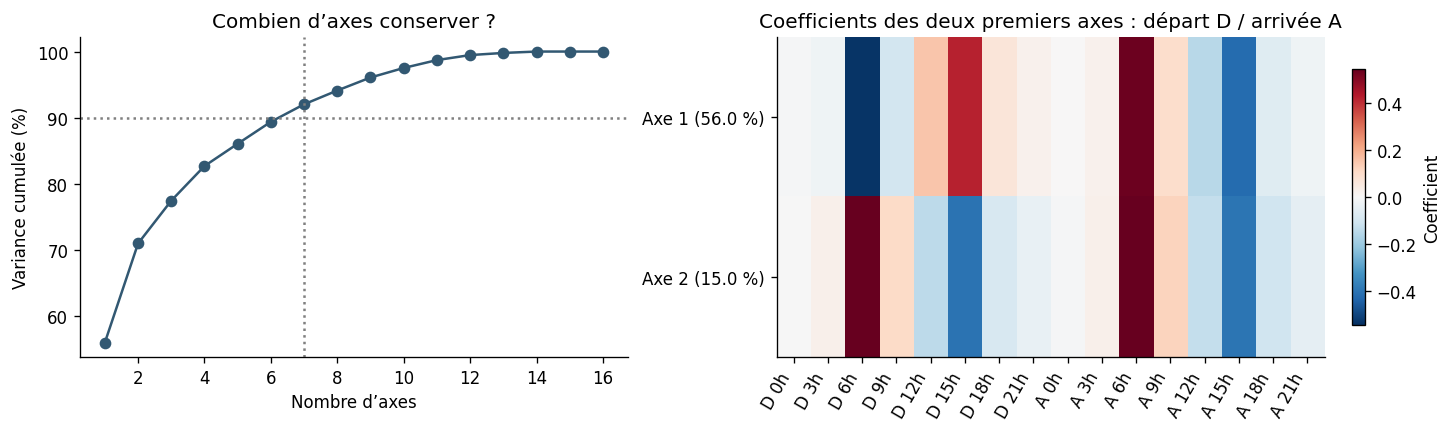

In [8]:
# Figure 2 : lecture factorielle, avant de nommer les profils.
fig,axes=plt.subplots(1,2,figsize=(12,3.5),layout='constrained')
axes[0].plot(np.arange(1,17),100*flow_pca.explained_variance_ratio_.cumsum(),'o-',color='#325872')
axes[0].axhline(90,color='grey',ls=':')
axes[0].axvline(flow_n_axes,color='grey',ls=':')
axes[0].set(xlabel='Nombre d’axes',ylabel='Variance cumulée (%)',title='Combien d’axes conserver ?')
loadings=flow_pca.components_[:2]
bound=np.abs(loadings).max()
im=axes[1].imshow(loadings,aspect='auto',cmap='RdBu_r',vmin=-bound,vmax=bound)
axes[1].set_xticks(range(16),[f'D {3*i}h'for i in range(8)]+[f'A {3*i}h'for i in range(8)],rotation=60,ha='right')
axes[1].set_yticks([0,1],[f'Axe {i+1} ({100*flow_pca.explained_variance_ratio_[i]:.1f} %)'for i in range(2)])
axes[1].set_title('Coefficients des deux premiers axes : départ D / arrivée A')
fig.colorbar(im,ax=axes[1],label='Coefficient',shrink=.8)
plt.show()

L'ACP concentre une grande partie de la variance dans les premiers axes ; sept suffisent pour dépasser 90 %. Le premier axe (environ 56 %) oppose les deux sens d'échange : les coefficients matin/fin de journée et départ/arrivée ont des signes opposés. Le deuxième (environ 15 %) décrit davantage un rythme commun aux deux extrémités. Leur signe est arbitraire ; ils ne sont pas des corrélations avec un motif de déplacement.

Trois groupes donnent la meilleure silhouette parmi les K testés. Les noms sont attribués après lecture des signatures : sens vers les pôles relativement récepteurs le matin, sens inverse et liaisons moins polarisées.

,Part_pct,Durée_min,Matin_pct,Soir_pct,Weekend_pct
profil_liaison,,,,,
Vers les pôles récepteurs du matin,13.9,10.0,43.8,16.1,15.8
Liaisons moins polarisées,72.1,12.0,12.9,29.6,26.3
Sens inverse,14.0,10.0,8.4,37.6,14.9


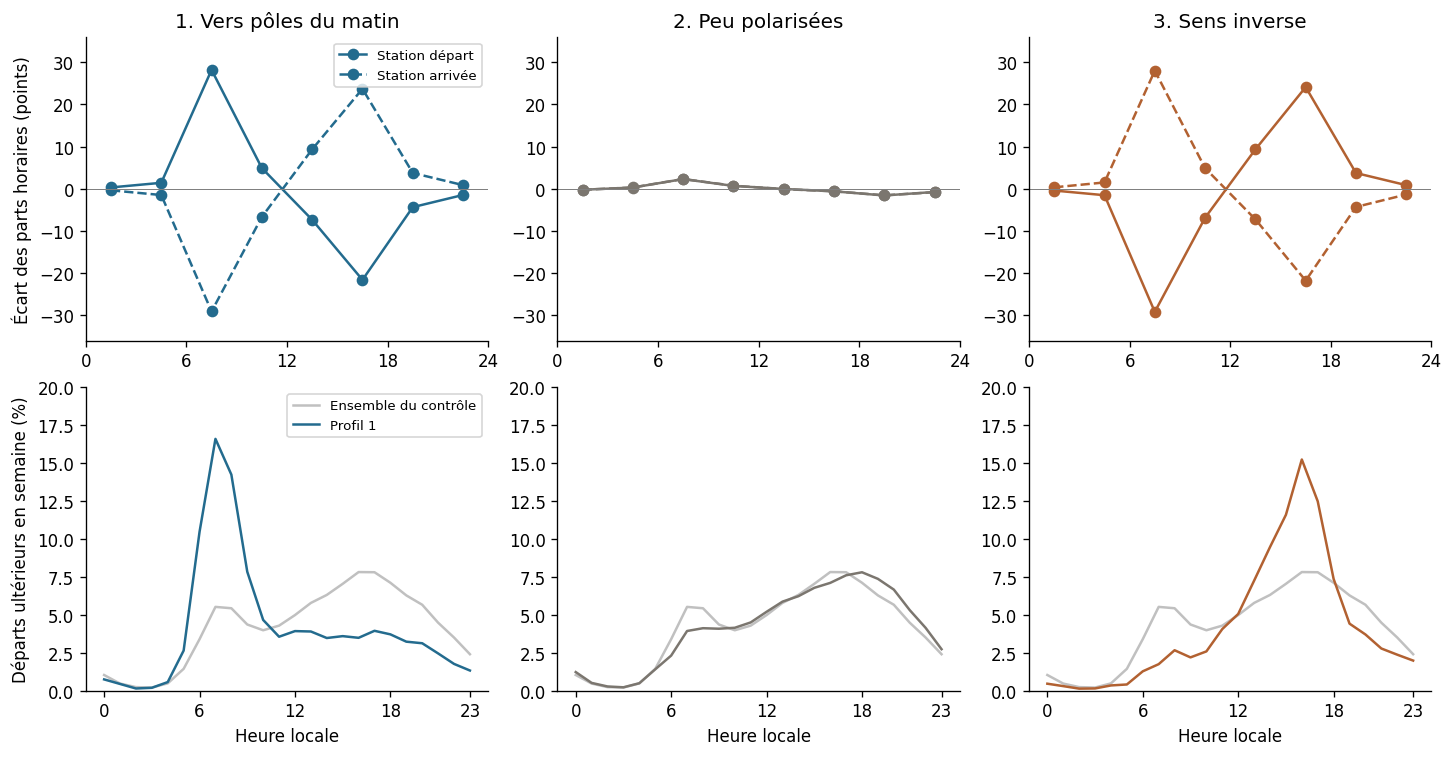

In [9]:
flow_names = {1:'Vers les pôles récepteurs du matin',
              2:'Liaisons moins polarisées',3:'Sens inverse'}
assert flow_k == 3, 'La lecture des profils doit être revue si le nombre de groupes change.'
final_trips = flow_trips.loc[flow_trips.period.eq('test')].copy()
final_trips['morning'] = final_trips.local_start_hour.between(6,10,inclusive='left')
final_trips['evening'] = final_trips.local_start_hour.between(16,20,inclusive='left')
final_trips['prolonged'] = final_trips.forme_trajet.eq(2)
flow_profiles = final_trips.groupby('profil_liaison').agg(
    Effectif=('trip_row','size'), Durée_min=('duration_min','median'),
    Matin_pct=('morning',lambda s:100*s.mean()), Soir_pct=('evening',lambda s:100*s.mean()),
    Weekend_pct=('weekend',lambda s:100*s.mean()),
    Durée_élevée_pct=('prolonged',lambda s:100*s.mean()))
flow_profiles.insert(1,'Part_pct',100*flow_profiles.Effectif/len(final_trips))
display(flow_profiles[['Part_pct','Durée_min','Matin_pct','Soir_pct','Weekend_pct']].rename(index=flow_names).round(1))


# Figure 3 : signatures et usages observés ensuite, sur la période finale.
colors=['#236b8e','#7b766f','#b26131']
signature_means=flow_trips.groupby('profil_liaison')[flow_columns].mean()
weekday_final=final_trips.loc[final_trips.weekend.eq(0)]
hourly=pd.crosstab(weekday_final.profil_liaison,np.floor(weekday_final.local_start_hour).astype(int)).reindex(columns=range(24),fill_value=0)
hourly=100*hourly.div(hourly.sum(axis=1),axis=0)
global_hour=np.bincount(np.floor(weekday_final.local_start_hour).astype(int),minlength=24)
global_hour=100*global_hour/global_hour.sum()
fig,axes=plt.subplots(2,3,figsize=(12,6.2),layout='constrained')
for i,k in enumerate([1,2,3]):
    means=signature_means.loc[k]
    axes[0,i].plot(np.arange(8)*3+1.5,100*means.iloc[:8],'-o',color=colors[i],label='Station départ')
    axes[0,i].plot(np.arange(8)*3+1.5,100*means.iloc[8:],'--o',color=colors[i],label='Station arrivée')
    axes[0,i].axhline(0,color='grey',lw=.6)
    axes[0,i].set(title=f'{k}. '+['Vers pôles du matin','Peu polarisées','Sens inverse'][i],xticks=[0,6,12,18,24],ylim=(-36,36))
    axes[1,i].plot(range(24),global_hour,color='silver',label='Ensemble du contrôle')
    axes[1,i].plot(range(24),hourly.loc[k],color=colors[i],label=f'Profil {k}')
    axes[1,i].set(xlabel='Heure locale',xticks=[0,6,12,18,23],ylim=(0,max(20,hourly.to_numpy().max()*1.1)))
axes[0,0].set_ylabel('Écart des parts horaires (points)')
axes[1,0].set_ylabel('Départs ultérieurs en semaine (%)')
axes[0,0].legend(fontsize=8)
axes[1,0].legend(fontsize=8)
plt.show()

**Résultat sur la période finale :** le sens vers les pôles du matin représente environ 14 % des trajets documentés, le sens inverse 14 %, et les liaisons moins polarisées 72 %. Les deux sens ont des horaires ultérieurs différents, alors que cette heure du trajet n'était pas une variable active.

Un rythme relatif de station ne prouve pas un trajet vers le travail. Le sens inverse ne démontre pas que les mêmes personnes effectuent un aller-retour. Le grand groupe peu polarisé reste hétérogène.

## 4. Évaluer les résultats retenus

La stabilité est examinée en réapprenant les modèles sur d'autres échantillons et en laissant des systèmes hors ajustement. Pour la lecture physique, on teste aussi les extrêmes et la précision des durées. Pour la lecture fonctionnelle, on teste les axes, le lissage et des signatures recalculées sur une période ultérieure.

L'ARI mesure l'accord entre partitions, pas leur vérité. Les silhouettes des deux analyses ne sont pas directement comparables, car leurs variables et leurs distances diffèrent.

**Reproductibilité :** tous les contrôles de cette section, y compris les diagnostics
complémentaires GPS, marges, concentration et bootstrap, sont recalculés lors d’une
exécution complète. Les graines et paramètres sont fixés ; les versions des bibliothèques,
les données et l’ordre des lignes peuvent néanmoins modifier les chiffres. Les sorties
enregistrées ne remplacent pas une réexécution dans l’ordre. Les essais historiques du
bilan A–J restent explicitement distingués des contrôles reproduits ici.


In [10]:
physical_checks = []
def refit_motion(train_indices, evaluation_indices, values=log_motion, seed=42):
    scaler = StandardScaler().fit(values[train_indices])
    with threadpool_limits(limits=2):
        model = GaussianMixture(n_components=physical_k,n_init=4,max_iter=300,
            reg_covar=1e-4,random_state=seed).fit(scaler.transform(values[train_indices]))
    return model.predict(scaler.transform(values[evaluation_indices]))
for seed in [11,73]:
    sample = np.random.default_rng(seed).choice(period_ids['train'],80000,replace=False)
    pred = refit_motion(sample,physical_test,seed=seed)
    physical_checks.append((f'Autre échantillon ({seed})',adjusted_rand_score(motion_raw[physical_test],pred)))
limits = trips.iloc[period_ids['train']][['duration_min','displacement_rate_kmh']].quantile(.99)
not_extreme = (trips.duration_min.le(limits.duration_min)&trips.displacement_rate_kmh.le(limits.displacement_rate_kmh)).to_numpy()
sample = np.random.default_rng(42).choice(period_ids['train'][not_extreme[period_ids['train']]],80000,replace=False)
pred = refit_motion(sample,physical_test)
physical_checks.append(('Sans extrêmes à l’entraînement',adjusted_rand_score(motion_raw[physical_test],pred)))
jittered = log_motion.copy()
jittered[:,0] = np.log(trips.duration_min.to_numpy()+np.random.default_rng(42).uniform(-.5,.5,len(trips)))
pred = refit_motion(physical_train,physical_test,values=jittered)
physical_checks.append(('Perturbation de ±30 secondes',adjusted_rand_score(motion_raw[physical_test],pred)))
del jittered
a,b = next(GroupShuffleSplit(n_splits=1,test_size=.2,random_state=2026).split(
    period_ids['train'],groups=trips.iloc[period_ids['train']].city_id))
sample = np.random.default_rng(42).choice(period_ids['train'][a],80000,replace=False)
heldout_cities = set(trips.iloc[period_ids['train'][b]].city_id)
evaluation = physical_test[trips.iloc[physical_test].city_id.isin(heldout_cities)]
pred = refit_motion(sample,evaluation)
physical_checks.append(('Villes exclues de l’entraînement',adjusted_rand_score(motion_raw[evaluation],pred)))
physical_checks = pd.DataFrame(physical_checks,columns=['Contrôle','ARI']).set_index('Contrôle')

route_keys = ['city_id','station_id_start','station_id_end','propulsion_context']
route_reference = trips.loc[trips.period.eq('train')].dropna(subset=route_keys).groupby(route_keys).duration_min.agg(['median','size'])
route_reference = route_reference.loc[route_reference['size'].ge(20)]
route_check = trips.loc[trips.period.eq('test')].join(route_reference,on=route_keys,validate='many_to_one').dropna(subset=['median'])
route_check['relative_duration'] = route_check.duration_min/route_check['median']
route_ratios = route_check.groupby('forme_trajet').relative_duration.median()


flow_checks = []
def refit_flow(values,train_indices,evaluation_indices,seed=42,n_axes=None):
    pca = PCA(svd_solver='full').fit(values[train_indices])
    n = int(np.searchsorted(pca.explained_variance_ratio_.cumsum(),.9)+1) if n_axes is None else n_axes
    with threadpool_limits(limits=2):
        model = KMeans(n_clusters=flow_k,n_init=10,random_state=seed).fit(pca.transform(values[train_indices])[:,:n])
    return model.predict(pca.transform(values[evaluation_indices])[:,:n])
for seed in [11,73]:
    sample = np.random.default_rng(seed).choice(flow_pools['train'],80000,replace=False)
    pred = refit_flow(flow_X,sample,flow_test,seed)
    flow_checks.append((f'Autre échantillon ({seed})',adjusted_rand_score(flow_raw[flow_test],pred)))
a,b = next(GroupShuffleSplit(n_splits=1,test_size=.2,random_state=2026).split(
    flow_pools['train'],groups=flow_trips.iloc[flow_pools['train']].city_id))
sample = np.random.default_rng(42).choice(flow_pools['train'][a],80000,replace=False)
heldout_flow_cities = set(flow_trips.iloc[flow_pools['train'][b]].city_id)
evaluation = flow_test[flow_trips.iloc[flow_test].city_id.isin(heldout_flow_cities)]
pred = refit_flow(flow_X,sample,evaluation)
flow_checks.append(('Villes exclues des centres',adjusted_rand_score(flow_raw[evaluation],pred)))
for axes in [2,5,14]:
    pred = refit_flow(flow_X,flow_train,flow_test,n_axes=axes)
    flow_checks.append((f'{axes} axes au lieu de {flow_n_axes}',adjusted_rand_score(flow_raw[flow_test],pred)))
for alpha in [1,6]:
    alternative,_ = station_signatures(events.loc[events.old],alpha=alpha)
    attached,_ = attach_signatures(flow_trips[trips.columns],alternative)
    assert attached.trip_row.tolist() == flow_trips.trip_row.tolist()
    values = attached[flow_columns].to_numpy()
    pred = refit_flow(values,flow_train,flow_test)
    flow_checks.append((f'Lissage {alpha} au lieu de 3',adjusted_rand_score(flow_raw[flow_test],pred)))
flow_checks = pd.DataFrame(flow_checks,columns=['Contrôle','ARI']).set_index('Contrôle')

# Période indépendante pour vérifier la stabilité des contextes, sans réapprentissage.
future_signatures,_ = station_signatures(events.loc[~events.old],min_events=60)
future_attached,_ = attach_signatures(flow_trips[trips.columns],future_signatures)
common_indices = flow_trips.index[flow_trips.trip_row.isin(future_attached.trip_row)].to_numpy()
assert np.array_equal(flow_trips.loc[common_indices,'trip_row'],future_attached.trip_row)
future_Z = flow_pca.transform(future_attached[flow_columns].to_numpy())[:,:flow_n_axes]
future_labels = flow_model.predict(future_Z)
context_ari = adjusted_rand_score(flow_raw[common_indices],future_labels)
context_agreement = np.mean(flow_raw[common_indices]==future_labels)
margin_checks = []
for threshold in [.15,.25,.35]:
    keep = flow_trips.loc[common_indices,'margin'].ge(threshold).to_numpy()
    margin_checks.append({'Marge minimale':threshold,'Couverture commune (%)':100*keep.mean(),
        'Même profil ultérieur (%)':100*np.mean(flow_raw[common_indices][keep]==future_labels[keep])})
margin_checks = pd.DataFrame(margin_checks)

# Effet horaire final à l'intérieur des systèmes, sans sélectionner par la marge.
by_city = final_trips.loc[final_trips.weekend.eq(0)].groupby(['city_id','profil_liaison']).agg(n=('trip_row','size'),morning=('morning','mean')).unstack()
supported = by_city['n'][1].ge(30)&by_city['n'][3].ge(30)
city_effect = 100*(by_city.loc[supported,('morning',1)]-by_city.loc[supported,('morning',3)])
bootstrap = np.random.default_rng(2026).choice(city_effect.to_numpy(),size=(2000,len(city_effect)),replace=True)
city_interval = np.quantile(np.median(bootstrap,axis=1),[.025,.975])
city_max = flow_trips.groupby('profil_liaison').city_id.apply(lambda s:s.value_counts(normalize=True).max())
route_max = flow_trips.groupby('profil_liaison').apply(
    lambda g:g.groupby(['city_id','station_id_start','station_id_end']).size().max()/len(g),include_groups=False)

def station_offset(frame,side):
    p1,p2 = np.deg2rad(frame[f'lat_{side}']),np.deg2rad(frame[f'station_{side}_lat'])
    dl = np.deg2rad(frame[f'lon_{side}']-frame[f'station_{side}_lon'])
    a = np.sin((p1-p2)/2)**2+np.cos(p1)*np.cos(p2)*np.sin(dl/2)**2
    return 12742.0176*np.arcsin(np.sqrt(np.clip(a,0,1)))
gps_supported = station_offset(final_trips,'start').le(.25)&station_offset(final_trips,'end').le(.25)
gps_effect = final_trips.loc[gps_supported&final_trips.weekend.eq(0)].groupby('profil_liaison').morning.mean()*100


evaluation_summary=pd.DataFrame([
    {'Lecture':'Physique','Contrôle':'Autres échantillons, extrêmes, arrondis, villes exclues',
     'ARI minimal':physical_checks.ARI.min()},
    {'Lecture':'Fonctionnelle','Contrôle':'Échantillons, villes exclues, axes et lissage',
     'ARI minimal':flow_checks.ARI.min()},
    {'Lecture':'Fonctionnelle','Contrôle':'Contexte réestimé sur une période ultérieure',
     'ARI minimal':context_ari}])
display(evaluation_summary.round(3).set_index('Lecture'))
print(f'Contexte réestimé : {100*context_agreement:.1f} % de labels identiques sur {len(common_indices):,} trajets ; '
      'les frontières temporelles sont moins stables que les centres rééchantillonnés.')
print(f'Écart matinal médian entre les deux sens : {city_effect.median():.1f} points dans '
      f'{len(city_effect)} systèmes suffisamment représentés ; même signe dans {100*city_effect.gt(0).mean():.1f} % des systèmes.')
print(f'À même liaison et propulsion, durée médiane relative : {route_ratios.loc[1]:.2f} et {route_ratios.loc[2]:.2f}, '
      f'sur {len(route_check):,} trajets avec référence historique.')

,Contrôle,ARI minimal
Lecture,,
Physique,"Autres échantillons, extrêmes, arrondis, ville...",0.971
Fonctionnelle,"Échantillons, villes exclues, axes et lissage",0.941
Fonctionnelle,Contexte réestimé sur une période ultérieure,0.636


Contexte réestimé : 88.9 % de labels identiques sur 664,328 trajets ; les frontières temporelles sont moins stables que les centres rééchantillonnés.
Écart matinal médian entre les deux sens : 36.7 points dans 63 systèmes suffisamment représentés ; même signe dans 98.4 % des systèmes.
À même liaison et propulsion, durée médiane relative : 0.94 et 2.37, sur 125,940 trajets avec référence historique.


**Lecture critique :** les deux familles physiques résistent aux contrôles réalisés. Les profils fonctionnels sont stables entre échantillons, mais changent davantage quand les rythmes des stations évoluent. La bonne stabilité ne démontre pas des populations naturellement séparées.

La lecture fonctionnelle concerne environ 60 % du fichier : les systèmes et stations peu renseignés sont sous-représentés. Le type de vélo reflète aussi l'offre des systèmes ; il ne permet pas d'inférer une préférence individuelle.

## 5. Croiser les deux lectures sur les mêmes trajets

On mesure ici la part de la famille physique à durée élevée dans chaque profil fonctionnel, exclusivement sur les trajets de contrôle qui disposent des deux labels. Les combinaisons ne sont pas considérées comme six nouvelles classes.

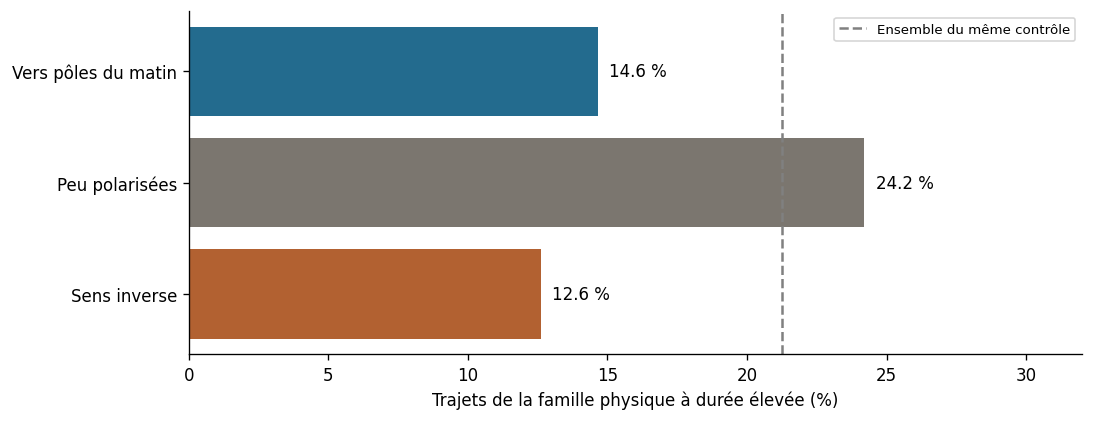

Contrôle par système : 59 systèmes comparables, écart médian 6.0 points ; écart positif dans 83.1 % des systèmes.


In [11]:
cross_counts=pd.crosstab(final_trips.profil_liaison,final_trips.forme_trajet).reindex(index=[1,2,3],columns=[1,2],fill_value=0)
cross_percent=100*cross_counts.div(cross_counts.sum(axis=1),axis=0)
overall_prolonged=100*final_trips.forme_trajet.eq(2).mean()
fig,ax=plt.subplots(figsize=(9,3.4),layout='constrained')
ax.barh(['Vers pôles du matin','Peu polarisées','Sens inverse'],cross_percent[2],color=colors)
ax.axvline(overall_prolonged,color='grey',ls='--',label='Ensemble du même contrôle')
for i,value in enumerate(cross_percent[2]):ax.text(value+.4,i,f'{value:.1f} %',va='center')
ax.set(xlabel='Trajets de la famille physique à durée élevée (%)',xlim=(0,32))
ax.invert_yaxis()
ax.legend(fontsize=8)
plt.show()

# Contrôle descriptif du croisement à l'intérieur des systèmes.
cross_control=final_trips.assign(mixed=final_trips.profil_liaison.eq(2),long=final_trips.forme_trajet.eq(2))
within_city=cross_control.groupby(['city_id','mixed']).agg(n=('trip_row','size'),long=('long','mean')).unstack('mixed')
eligible=within_city['n'][True].ge(30)&within_city['n'][False].ge(30)
within_city_delta=100*(within_city.loc[eligible,('long',True)]-within_city.loc[eligible,('long',False)])
print(f'Contrôle par système : {len(within_city_delta)} systèmes comparables, '
      f'écart médian {within_city_delta.median():.1f} points ; '
      f'écart positif dans {100*within_city_delta.gt(0).mean():.1f} % des systèmes.')

**Apport du croisement :** les liaisons peu polarisées contiennent environ 24 % de trajets à durée élevée, contre 13–15 % dans les deux sens polarisés. Le contrôle par système indique dans quelle mesure l'association globale se retrouve localement. Il s'agit d'une association descriptive, sans explication causale ni motif individuel observé.

Dans les 59 systèmes suffisamment représentés, cet écart est positif dans 83,1 % des cas et vaut six points à la médiane. L’association existe donc aussi localement, mais elle est moins forte et non universelle.

## 6. Bilan des recherches A–J

Les lignes suivantes résument les essais réalisés pendant l'exploration. **A, E et F sont reproduits dans ce notebook ; H est repris sous forme de contrôle à liaison comparable.** Les autres résultats sont historiques, consignés dans `choix.md`, et ne sont pas tous recalculés à chaque exécution.

| Repère | Hypothèse et méthode | Résultat important | Décision |
|---|---|---|---|
| **A — Préparation** | Jointures et représentations cohérentes rendent les trajets comparables. | Heure locale, unités, absences et clés contrôlées ; périmètres explicités. | Base commune au début. |
| **B — Temporel** | ACP + K-means sur durée/taux et moment distingue des usages. | Quatre descriptions lisibles ; continuum horaire et sensibilité aux extrêmes. | Résultat secondaire ; ne pas doubler les familles physiques. |
| **C — Spatial initial** | Centralité relative + weekend distingue les déplacements. | Rapprochements/éloignements utiles ; groupe weekend favorisé par la variable fournie. Centre approximatif. | Complément exploratoire. |
| **D — Combinaison globale** | Fusionner temps et espace donne des profils plus riches. | Groupes surtout temporels ; peu de différenciation spatiale supplémentaire. | Essai négatif : pas de gain démontré. |
| **E — Physique** | GMM sur log(durée), log(déplacement) distingue des formes de voyage. | Deux familles stables : durée faible ou élevée pour le déplacement obtenu. | Résultat retenu, avec incertitude. |
| **F — Fonctionnel** | Signatures des stations → ACP → K-means révèlent des usages de liaisons. | Deux sens polarisés et un groupe peu polarisé ; horaires ultérieurs cohérents. Couverture 60 %. | Résultat principal retenu. |
| **G — Géométrie enrichie** | La variation radiale masque les liaisons entre secteurs différents. | Niveau détaillé à cinq groupes : transversaux ≈13,3 %, même secteur excentré ≈18 %. Meilleure silhouette à trois ; dépendance au centre. | Ouverture descriptive, pas preuve de cinq classes naturelles. |
| **H — Durée relative** | Comparer à l'historique de la même liaison et propulsion précise l'interprétation. | Confirme largement les familles physiques. Le GMM de ratios donne deux composantes ; écarts courts/longs sont des sous-descriptions. | Contrôle retenu, sans nouvelle classe revendiquée. |
| **I — Rythmes de liaisons** | Les fréquences historiques heure × semaine/weekend décomposent le groupe peu polarisé. | Meilleure silhouette ≈0,133 ; pas de sous-profils assez distincts. | Essai négatif. |
| **J — HDBSCAN** | Une méthode de densité découvre des groupes plus naturels. | Dans la représentation testée, retrouve surtout semaine/weekend ; pas de structure d'usage nouvelle convaincante. | Essai négatif, limité à cette représentation. |

Les essais temporels, spatiaux et de densité ont guidé les choix retenus. Ils ne sont pas présentés comme dix résultats indépendants.

## Conclusion

**Deux lectures complémentaires répondent à la question :** la relation durée–déplacement distingue des formes de voyage ; le contexte historique des stations distingue des rythmes d'échange. Leur croisement montre davantage de durées élevées parmi les liaisons peu polarisées.

**Limites à annoncer :** distance à vol d'oiseau et durée totale, sélection préalable du fichier inconnue, couverture station partielle, frontières graduelles et validation interne. Les références historiques et les rythmes évoluent. Les caractéristiques des vélos restent descriptives.

Les groupes ne permettent pas d'affirmer travail, balade, sport, parent/enfant ou identité d'usager. La principale amélioration future serait une validation sur des données nouvelles et une interprétation contextualisée des liaisons peu polarisées, plutôt qu'une multiplication des algorithmes.

Références méthodologiques : [ACP](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html), [clustering et évaluation](https://scikit-learn.org/stable/modules/clustering.html), [mélanges gaussiens](https://scikit-learn.org/stable/modules/mixture.html), [composantes, groupes et entropie](https://pmc.ncbi.nlm.nih.gov/articles/PMC2953822/). Les chiffres viennent des données fournies.

In [12]:
assert len(trips)==physical_profiles.Effectif.sum()
assert len(final_trips)==flow_profiles.Effectif.sum()==cross_counts.to_numpy().sum()
assert np.allclose(cross_percent.sum(axis=1),100)
assert np.isfinite(motion_X).all() and np.isfinite(flow_X).all()
assert set(flow_pools['train']).isdisjoint(flow_pools['test'])
assert set(flow_pools['validation']).isdisjoint(flow_pools['test'])
assert trips.trip_row.is_unique and flow_trips.trip_row.is_unique
assert len(trips)==n_trips
print('Vérifications terminées : jointures, effectifs, périmètres, matrices et périodes cohérents.')

Vérifications terminées : jointures, effectifs, périmètres, matrices et périodes cohérents.
